# Metodos de Primer Orden

- Descenso por gradient
- Momento o inercia
- Gradiente Acelerado de Nestorov
- AdaGrad y RMSprop
- Adam

## Observacion
En este notebook, se intenta reproducir el codigo que aparece en el libro de texto de Brunton.

In [ ]:
import numpy as np

In [ ]:
# ---------------------------------------------------------------------------
# 2.1  Gradient Descent
# ---------------------------------------------------------------------------
#
# Code 2.1: Gradient descent code for a quadratic objective function.
# (La listada está partida por un salto de página con una figura en medio:
#  `fvals.append(...)` y el `return` aparecen en la página siguiente.)


def quadraticObjective(X, A, b, c):
  # f(x) = 0.5*x^T A x + b^Tx + c
    return 0.5 * X.T @ A @ X + b.T @ X + c


def gradientDescent(A, b, c, x0, step_size, max_iter):
    xvals = [np.array(x0)]  # Initialize with x0, f(x0)
    fvals = [quadraticObjective(np.array(x0), A, b, c)]
    x = np.array(x0, dtype=float)

    for _ in range(max_iter):
        grad = A @ x + b  # Gradient of objective function
        x = x - step_size * grad
        xvals.append(x.copy())
        fvals.append(quadraticObjective(x, A, b, c))

    return np.array(xvals), np.array(fvals)


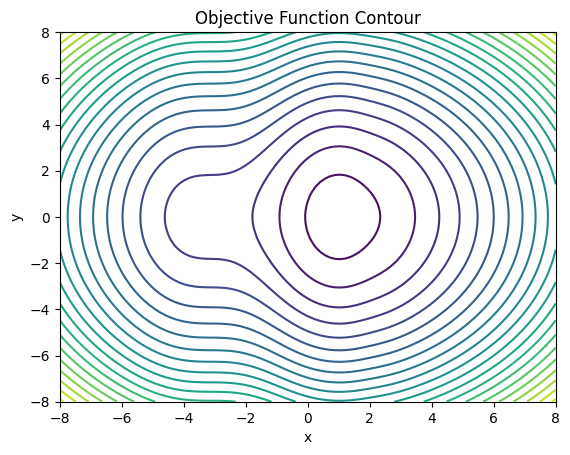

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

# Visualize a contour plot of the function with matplotlib
#     f(x, y) = 15 e^{-0.25 (x+2)^2} + 0.5 e^{-2 (x-2)^2} + x^2 + y^2

X, Y = np.meshgrid(np.linspace(-8, 8, 100), np.linspace(-8, 8, 100))
Z = 15.0 * np.exp(-0.25 * (X + 2.0) ** 2) + 0.5 * np.exp(-2.0 * (X - 2.0) ** 2) + X ** 2 + Y ** 2
# show the image
plt.contour(X, Y, Z, levels=20)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Objective Function Contour')
plt.show()

In [ ]:
# ---------------------------------------------------------------------------
# 2.2  Momentum Methods
# ---------------------------------------------------------------------------
#
# EDITORIAL: el listado de Nesterov llama a `double_well_potential` y a
# `grad_func`, que el libro nunca imprime.  Se definen aquí a partir de la
# Eq. (2.24) para que el código sea ejecutable:
#
#     f(x, y) = 15 e^{-0.25 (x+2)^2} + 0.5 e^{-2 (x-2)^2} + x^2 + y^2


def double_well_potential(x, y):
    """Eq. (2.24): potencial de doble pozo con un punto casi degenerado."""
    return (15.0 * np.exp(-0.25 * (x + 2.0) ** 2)
            + 0.5 * np.exp(-2.0 * (x - 2.0) ** 2)
            + x ** 2 + y ** 2)


def grad_func(x, y):
    """Gradiente de la Eq. (2.24) (derivadas analíticas de la ecuación)."""
    e1 = np.exp(-0.25 * (x + 2.0) ** 2)
    e2 = np.exp(-2.0 * (x - 2.0) ** 2)
    grad_x = -7.5 * (x + 2.0) * e1 - 2.0 * (x - 2.0) * e2 + 2.0 * x
    grad_y = 2.0 * y
    return np.array([grad_x, grad_y])

# EDITORIAL: descenso de gradiente simple sobre la Eq. (2.24).  El libro
# compara en la Fig. 2.6 "gradient descent" contra "Nesterov's Accelerated"
# pero solo imprime el listado de Nesterov.
def gradient_descent_2d(start, grad_func, step_size, max_iter):
    x = np.array(start, dtype=float)
    trajectory = [x.copy()]
    values = [double_well_potential(x[0], x[1])]

    for _ in range(max_iter):
        grad = grad_func(x[0], x[1])
        x = x - step_size * grad
        trajectory.append(x.copy())
        values.append(double_well_potential(x[0], x[1]))

    return np.array(trajectory), np.array(values)


# Eqs. (2.18)-(2.19), descrito en el texto
# pero no impreso como listado.
def momentum_gradient_descent(start, grad_func, step_size, momentum, max_iter):
    x = np.array(start, dtype=float)
    velocity = np.zeros(2) # (0,0)
    trajectory = [x.copy()]
    values = [double_well_potential(x[0], x[1])]

    for _ in range(max_iter):
        velocity = momentum * velocity - step_size * grad_func(x[0], x[1])
        x = x + velocity
        trajectory.append(x.copy())
        values.append(double_well_potential(x[0], x[1]))

    return np.array(trajectory), np.array(values)



In [ ]:
# ---------------------------------------------------------------------------
# Siempre 2.2  Nesterov Accelerated Gradient NAG
# ---------------------------------------------------------------------------

def nesterov_accelerated_gradient(start, grad_func, step_size,
                                  momentum, max_iter):
    # sin inicializar; se añade la inicialización mínima que exige.
    x = np.array(start, dtype=float)
    velocity = np.zeros(2)
    trajectory = [x.copy()]
    values = [double_well_potential(x[0], x[1])]

    for _ in range(max_iter):
        y = x + momentum * velocity
        grad = grad_func(y[0], y[1])
        velocity = momentum * velocity - step_size * grad
        x = x + velocity
        trajectory.append(x.copy())
        values.append(double_well_potential(x[0], x[1]))

    return np.array(trajectory), np.array(values)

In [ ]:
# ---------------------------------------------------------------------------
# 2.3  Stochastic Gradient Descent and ADAM
# ---------------------------------------------------------------------------

# Generación del problema de regresión lineal con ruido.
N = 2000  # number of samples
A = np.random.randn(N, 2)  # design matrix
true_x = np.array([2.0, -3.0])  # true slopes
true_b = 5.0

# True y = A * x + b plus some noise
# creacion de datos sinteticos para minimos cuadrados
noise_std = 0.5
noise = noise_std * np.random.randn(N)
y = A.dot(true_x) + true_b + noise


def predict(A, x, b):
    # A: shape (batch_size, 2)
    # x: shape (2,)
    # b: scalar
    # A*x + b
    return A.dot(x) + b  # shape (batch_size,)


def mean_squared_error(y_true, y_pred):
  # funcion objetivo es minimizar el error
    return np.mean((y_true - y_pred) ** 2)


def batch_gradients(A_batch, y_batch, x, b):
    # batch = lote
    # A_batch, x, b: same shape
    # y_batch: shape (batch_size,)
    batch_size = A_batch.shape[0]
    y_pred = predict(A_batch, x, b)
    residuals = (y_pred - y_batch)
    grad_x = (2.0 / batch_size) * A_batch.T.dot(residuals)
    grad_b = (2.0 / batch_size) * np.sum(residuals)
    return grad_x, grad_b


In [ ]:
def full_batch_gd(A, y, gamma=0.01, n_epochs=50):
    x = np.zeros(2)  # unknown parameter vector
    b = 0.0
    mse_history = []
    for epoch in range(n_epochs):
        grad_x, grad_b = batch_gradients(A, y, x, b)
        x -= gamma * grad_x
        b -= gamma * grad_b
        y_pred = predict(A, x, b)
        mse = mean_squared_error(y, y_pred)
        mse_history.append(mse)
    return x, b, mse_history


def mini_batch_sgd(A, y, batch_size=50, gamma=0.01, n_epochs=50):
    x = np.zeros(2)
    b = 0.0
    N = A.shape[0]
    mse_history = []
    for epoch in range(n_epochs):
        indices = np.random.permutation(N)    # Shuffle data
        for start in range(0, N, batch_size):
            end = start + batch_size
            batch_idx = indices[start:end]
            A_batch = A[batch_idx]
            y_batch = y[batch_idx]
            grad_x, grad_b = batch_gradients(A_batch, y_batch, x, b)
            x -= gamma * grad_x
            b -= gamma * grad_b
        # Check MSE after each epoch
        y_pred = predict(A, x, b)
        mse = mean_squared_error(y, y_pred)
        mse_history.append(mse)
    return x, b, mse_history

def sgd_batch1(A, y, gamma=0.001, n_epochs=50):
    x = np.zeros(2)
    b = 0.0
    N = A.shape[0]
    mse_history = []
    for epoch in range(n_epochs):
        indices = np.random.permutation(N)
        for i in indices:
            A_i = A[i:i + 1]        # shape (1,2)
            y_i = y[i:i + 1]        # shape (1,)
            grad_x, grad_b = batch_gradients(A_i, y_i, x, b)
            x -= gamma * grad_x
            b -= gamma * grad_b
        # MSE after epoch
        y_pred = predict(A, x, b)
        mse = mean_squared_error(y, y_pred)
        mse_history.append(mse)
    return x, b, mse_history



In [ ]:
# --- Ejemplo: SGD en un problema de regresión no lineal ---------------------

def true_poly(x):
    return (-10.0 * x ** 2) + (2.0 * x ** 4)


num_train = 50  # Small training set makes problem challenging
num_test = 50
x_train = np.linspace(-2, 2, num_train)  # data in range [-2,2]
y_train_true = true_poly(x_train)
noise_std = 2.0  # Add relatively large noise
noise_train = noise_std * np.random.randn(num_train)
y_train = y_train_true + noise_train
np.random.seed(2023)  # Test data (different seed)
x_test = np.linspace(-2, 2, num_test)
y_test_true = true_poly(x_test)
noise_test = noise_std * np.random.randn(num_test)
y_test = y_test_true + noise_test


def create_poly_features(x, degree=10):
    # Return matrix with columns [x^0, x^1, ..., x^degree]
    return np.column_stack([x ** i for i in range(degree + 1)])


X_train = create_poly_features(x_train, degree=10)
X_test = create_poly_features(x_test, degree=10)


def batch_gradient(X, y, w):
    # Compute gradient of MSE w.r.t. w: -2/N * X^T (y - Xw)
    N = X.shape[0]
    residuals = y - X.dot(w)
    grad = -(2.0 / N) * X.T.dot(residuals)
    return grad



## ADAM en NumPy, segun las Eqs. (2.34)-(2.36) del libro -------------------

 EDITORIAL: el libro implementa ADAM con PyTorch (que aqui no esta instalado).
 Las ecuaciones del propio capitulo bastan para escribirlo en NumPy (eqns 2.35-2.36):

$m_{k+1} = b_1 m_k + (1 - b_1) \nabla f(x_k)$          

$v_{k+1} = b_2 v_k + (1 - b_2) (\nabla f(x_k))^2$      

$m_k     = m_k / (1 - b_1^k)$                          

$v_k     = v_k / (1 - b_2^k)$                          

$x_{k+1} = x_k - \gamma m_k / (\sqrt{v_k} + eps)$      


In [ ]:
def adam(X, y, w0, grad_func, gamma=1e-2, beta1=0.9, beta2=0.999, eps=1e-8,
         n_epochs=5000, batch_size=None):
    """ADAM (Eqs. 2.34-2.36) sobre MSE de un modelo lineal w."""
    w = np.array(w0, dtype=float)
    m = np.zeros_like(w)
    v = np.zeros_like(w)
    N = X.shape[0]
    history = []
    for k in range(1, n_epochs + 1):
        if batch_size is None:
            idx = np.arange(N)
        else:
            idx = np.random.permutation(N)[:batch_size]
        grad = grad_func(X[idx], y[idx], w)
        m = beta1 * m + (1.0 - beta1) * grad
        v = beta2 * v + (1.0 - beta2) * grad ** 2
        m_hat = m / (1.0 - beta1 ** k)
        v_hat = v / (1.0 - beta2 ** k)
        w = w - gamma * m_hat / (np.sqrt(v_hat) + eps)
        history.append(np.mean((y - X.dot(w)) ** 2))
    return w, history


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

In [ ]:
def adam_pytorch_demo(X_train, y_train, X_test, y_test, n_epochs=5000, lr=1e-2):
    """ADAM de PyTorch sobre el problema polinomial.

    FIX: el libro escribe `optim.Adam(model.parameters(), gamma=1e-2)`, pero
    `torch.optim.Adam` no admite `gamma` (su hiperparámetro es `lr`), así que
    la línea tal cual lanza TypeError.  Se usa `lr=1e-2`, que es lo que el
    autor quiso escribir.
    """
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

    # Define a linear model (# features = # polynomial terms)
    model = nn.Linear(X_train.shape[1], 1)
    with torch.no_grad():  # Optional: initialize weights/bias to zero
        model.weight.zero_()
        model.bias.zero_()
    optimizer = optim.Adam(model.parameters(), lr=lr)  # FIX: `gamma` -> `lr`
    criterion = nn.MSELoss()
    adam_loss_history = []
    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)
        loss.backward()
        optimizer.step()
        adam_loss_history.append(loss.item())
        if (epoch + 1) % 200 == 0:
            print(f"Epoch {epoch+1}/{n_epochs}, Loss: {loss.item():.4f}")

    model.eval()     # Evaluate ADAM model
    with torch.no_grad():
        train_loss_adam = criterion(model(X_train_t), y_train_t).item()
        test_loss_adam = criterion(model(X_test_t), y_test_t).item()
    y_adam_train = model(X_train_t).detach().numpy().flatten()

    print(f"  ADAM  train MSE = {train_loss_adam:.4f}   test MSE = {test_loss_adam:.4f}")
    return {"loss_history": adam_loss_history,
            "train_mse": train_loss_adam,
            "test_mse": test_loss_adam,
            "y_train": y_adam_train}



In [ ]:
# ---------------------------------------------------------------------------
# 2.4  Newton's Method
# ---------------------------------------------------------------------------


def newtons_method(start, max_iter):
    trajectory = [np.array(start)]
    values = [objective_function(*start)]
    point = np.array(start, dtype=float)

    for _ in range(max_iter):
        grad = gradient(point[0], point[1])
        hess = hessian(point[0], point[1])
        hess_inv = np.linalg.inv(hess)
        point -= hess_inv @ grad
        trajectory.append(point.copy())
        values.append(objective_function(point[0], point[1]))

    return np.array(trajectory), np.array(values)



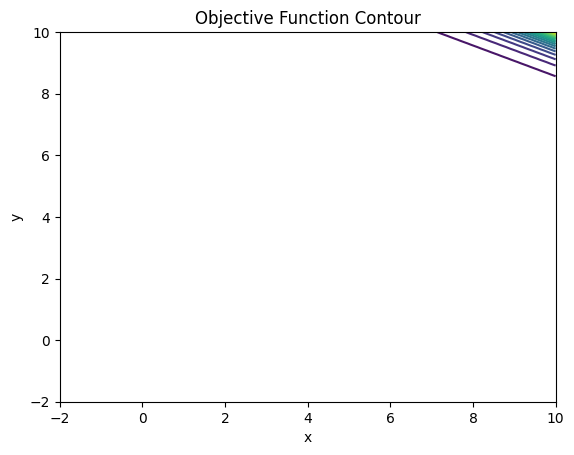

In [ ]:
# Define the objective function and its derivatives   (Eq. 2.7)
def objective_function(x, y):
    return np.exp(x + 2 * y - 0.2) + np.exp(x - 2 * y - 0.2) + np.exp(-x - 0.2)


def gradient(x, y):
    grad_x = np.exp(x + 2 * y - 0.2) + np.exp(x - 2 * y - 0.2) - np.exp(-x - 0.2)
    grad_y = 2 * np.exp(x + 2 * y - 0.2) - 2 * np.exp(x - 2 * y - 0.2)
    return np.array([grad_x, grad_y])


def hessian(x, y):
    h_xx = np.exp(x + 2 * y - 0.2) + np.exp(x - 2 * y - 0.2) + np.exp(-x - 0.2)
    h_xy = 2 * np.exp(x + 2 * y - 0.2) - 2 * np.exp(x - 2 * y - 0.2)
    h_yy = 4 * np.exp(x + 2 * y - 0.2) + 4 * np.exp(x - 2 * y - 0.2)
    return np.array([[h_xx, h_xy], [h_xy, h_yy]])

import matplotlib.pyplot as plt
%matplotlib inline

# create a contour graph using local variables to avoid overwriting global regression variables 'x' and 'y'
x_grid = np.linspace(-2, 10, 100)
y_grid = np.linspace(-2, 10, 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = objective_function(X, Y)
plt.contour(X, Y, Z, levels=20)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Objective Function Contour')
plt.show()

In [ ]:
# Regenerate original dataset variables to clean up the mismatched global state
np.random.seed(0)
N = 2000  # number of samples
A = np.random.randn(N, 2)  # design matrix
true_x = np.array([2.0, -3.0])  # true slopes
true_b = 5.0
noise_std = 0.5
noise = noise_std * np.random.randn(N)
y = A.dot(true_x) + true_b + noise

print("Global variables 'A' and 'y' successfully restored to N = 2000 samples.")

Global variables 'A' and 'y' successfully restored to N = 2000 samples.


In [ ]:
def gradient_descent_2d_generic(start, func, grad, step_size, max_iter):
    x = np.array(start, dtype=float)
    trajectory = [x.copy()]
    values = [func(x[0], x[1])]

    for _ in range(max_iter):
        x = x - step_size * grad(x[0], x[1])
        trajectory.append(x.copy())
        values.append(func(x[0], x[1]))

    return np.array(trajectory), np.array(values)

In [ ]:
def run_code_2_1():
    print("=" * 72)
    print("2.1  Gradient Descent  (Code 2.1)")
    print("=" * 72)
    A = np.array([[2, 1], [1, 3]])  # Positive-definite matrix
    b = np.array([0, 0])            # Linear term
    c = 0                           # Constant term
    x0 = np.array([-2.0, 0.0])      # Starting point
    step_size = 0.1                 # Learning rate
    N = 30                          # Maximum iterations

    xvals, fvals = gradientDescent(A, b, c, x0, step_size, N)
    print(f"  x0            = {x0}")
    print(f"  x final       = {xvals[-1]}   (minimo exacto = {np.linalg.solve(A, -b)})")
    print(f"  f(x0)         = {fvals[0]:.6f}")
    print(f"  f(x final)    = {fvals[-1]:.3e}")
    print(f"  iteraciones   = {len(fvals) - 1}")
    return {"xvals": xvals, "fvals": fvals, "A": A, "b": b, "x0": x0}

def run_code_2_2():
    print("=" * 72)
    print("2.2  Momentum Methods  (Nesterov sobre la Eq. 2.24)")
    print("=" * 72)
    # "This is then initialized with the initial condition (-5, 3) and run with
    #  a step size of gamma = 0.1, a momentum coefficient beta = 0.9 and a
    #  maximum number of iterations of 100."
    start = np.array([-5.0, 3.0])
    step_size = 0.1
    momentum = 0.9
    max_iter = 100

    gd_traj, gd_vals = gradient_descent_2d(start, grad_func, step_size, max_iter)
    mom_traj, mom_vals = momentum_gradient_descent(start, grad_func, step_size,
                                                   momentum, max_iter)
    nag_traj, nag_vals = nesterov_accelerated_gradient(start, grad_func, step_size,
                                                       momentum, max_iter)

    print(f"  f inicio           = {double_well_potential(*start):.4f}")
    for name, vals in (("Gradient Descent", gd_vals),
                       ("Momentum", mom_vals),
                       ("Nesterov", nag_vals)):
        print(f"  {name:18s}: f(k=10) = {vals[10]:8.3f}   "
              f"f(k=20) = {vals[20]:8.3f}   f(k=100) = {vals[-1]:8.4f}")
    print("  (Fig. 2.6 del libro: GD se atasca ~20.7 por el punto casi degenerado;")
    print("   Nesterov baja a ~2.65 mucho antes.)")
    return {"gd": (gd_traj, gd_vals), "momentum": (mom_traj, mom_vals),
            "nag": (nag_traj, nag_vals), "start": start}

def run_code_2_3():
    print("=" * 72)
    print("2.3  Stochastic Gradient Descent and ADAM")
    print("=" * 72)
    np.random.seed(0)
    x_fb, b_fb, mse_fb = full_batch_gd(A, y)
    x_mb, b_mb, mse_mb = mini_batch_sgd(A, y)
    x_s1, b_s1, mse_s1 = sgd_batch1(A, y)

    print(f"  full-batch GD : x = {x_fb}  b = {b_fb:.4f}  MSE final = {mse_fb[-1]:.4f}")
    print(f"  mini-batch SGD: x = {x_mb}  b = {b_mb:.4f}  MSE final = {mse_mb[-1]:.4f}")
    print(f"  SGD batch=1   : x = {x_s1}  b = {b_s1:.4f}  MSE final = {mse_s1[-1]:.4f}")
    print(f"  referencia (x* = {true_x}, b* = {true_b})")

    # Barrido de tamanos de lote (Fig. 2.9 del libro).
    for bs in (1, 10, 50, 200):
        np.random.seed(0)
        _, _, m = mini_batch_sgd(A, y, batch_size=bs)
        print(f"  mini-batch (batch={bs:4d}): MSE final = {m[-1]:.4f}")

    # Regresion polinomial de grado 10 sobre datos ruidosos.  El problema es
    # muy mal condicionado (cond ~ 1e8), por eso el libro lo resuelve con
    # ADAM (Fig. 2.11) y no con gradiente simple.
    w_adam, adam_hist = adam(X_train, y_train, np.zeros(X_train.shape[1]),
                             batch_gradient, gamma=1e-2, n_epochs=5000)
    mse_tr = np.mean((y_train - X_train.dot(w_adam)) ** 2)
    mse_te = np.mean((y_test - X_test.dot(w_adam)) ** 2)
    print(f"  polinomio grado 10 (ADAM, 5000 épocas): "
          f"MSE train = {mse_tr:.4f}, MSE test = {mse_te:.4f}")

    adam_torch = adam_pytorch_demo(X_train, y_train, X_test, y_test)
    return {"full_batch": (x_fb, b_fb, mse_fb),
            "mini_batch": (x_mb, b_mb, mse_mb),
            "sgd1": (x_s1, b_s1, mse_s1),
            "poly_w": w_adam, "adam": adam_torch}

def run_code_2_4():
    print("=" * 72)
    print("2.4  Newton's Method  (Eq. 2.7)")
    print("=" * 72)
    # "We use an initial condition of [-2, 1] and a max number of iterations
    #  of 30; for gradient descent, we use step size gamma = 0.05."
    start_point = np.array([-2.0, 1.0])
    max_iter = 30
    step_size = 0.05

    nm_trajectory, nm_values = newtons_method(start_point, max_iter)
    gd_trajectory, gd_values = gradient_descent_2d_generic(
        start_point, objective_function, gradient, step_size, max_iter)

    print(f"  f inicio            = {objective_function(*start_point):.6f}")
    print(f"  Newton  f(k=1..6)    = " +
          "  ".join(f"{v:.3e}" for v in nm_values[1:7]))
    print(f"  Newton  f final      = {nm_values[-1]:.3e}  en {len(nm_values)-1} pasos")
    print(f"  Newton  punto final  = {nm_trajectory[-1]}")
    print(f"  GD      f final      = {gd_values[-1]:.3e}")
    print(f"  (el libro: 'Within five steps, the Newton's method solver converges")
    print("   to near machine precision of the minimum.')")
    return {"newton": (nm_trajectory, nm_values),
            "gd": (gd_trajectory, gd_values)}




In [ ]:

# ---------------------------------------------------------------------------
# Figuras (opcionales)
# ---------------------------------------------------------------------------

def make_figures(res1, res2, res3, res4, outdir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(outdir, exist_ok=True)

    # Fig. 2.3 -- trayectorias de GD con tres tamanos de paso.
    A, b, x0 = res1["A"], res1["b"], res1["x0"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    gx, gy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    F = 0.5 * (gx ** 2 * A[0, 0] + 2 * gx * gy * A[0, 1] + gy ** 2 * A[1, 1]) \
        + b[0] * gx + b[1] * gy
    for ax, gamma, color in zip(axes, (0.01, 0.1, 0.543),
                                ("tab:blue", "tab:orange", "tab:green")):
        xv, fv = gradientDescent(A, b, 0.0, x0, gamma, 30)
        ax.contour(gx, gy, F, levels=20, colors="0.8")
        ax.plot(xv[:, 0], xv[:, 1], color=color, lw=1.6, label=f"gamma = {gamma}")
        ax.set_title(f"gamma = {gamma}")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
    fig.suptitle("Fig. 2.3  Gradient descent con distintos tamanos de paso")
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, "fig_2_3_descenso_gradiente.png"), dpi=140)
    plt.close(fig)

    # Fig. 2.6 -- GD vs Nesterov sobre la Eq. (2.24).
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    for (name, (traj, vals)), color in zip(
            (("Gradient Descent", res2["gd"]),
             ("Momentum", res2["momentum"]),
             ("Nesterov's Accelerated", res2["nag"])),
            ("tab:blue", "tab:orange", "tab:green")):
        ax.plot(np.arange(len(vals)), vals, color=color, lw=1.6, label=name)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Objective Function Value")
    ax.set_title("Fig. 2.6  GD vs Nesterov sobre la Eq. (2.24)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, "fig_2_6_nesterov.png"), dpi=140)
    plt.close(fig)

    # Fig. 2.13 -- GD vs Newton sobre la Eq. (2.7) (escala semilog).
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    for (name, (traj, vals)), color in zip(
            (("Gradient Descent", res4["gd"]),
             ("Newton's Method", res4["newton"])),
            ("tab:blue", "tab:orange")):
        ax.semilogy(np.arange(1, len(vals)), np.maximum(vals[1:], 1e-18),
                    color=color, lw=1.6, label=name)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Objective Value")
    ax.set_title("Fig. 2.13  GD vs Newton sobre la Eq. (2.7)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, "fig_2_13_newton.png"), dpi=140)
    plt.close(fig)

    # Fig. 2.9 -- convergencia de los tres metodos de SGD.
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    for (name, key), color in zip((("Full batch", "full_batch"),
                                   ("Mini-batch", "mini_batch"),
                                   ("SGD (batch=1)", "sgd1")),
                                  ("tab:blue", "tab:orange", "tab:green")):
        ax.plot(res3[key][2], color=color, lw=1.6, label=name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (on entire dataset)")
    ax.set_title("Fig. 2.9  Convergence de full-batch, mini-batch y SGD")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, "fig_2_9_sgd.png"), dpi=140)
    plt.close(fig)

    print(f"\nFiguras guardadas en {outdir}")




In [ ]:
import os

def main(argv=None):
    np.random.seed(0)
    res1 = run_code_2_1()
    res2 = run_code_2_2()
    res3 = run_code_2_3()
    res4 = run_code_2_4()

    print("=" * 72)
    print("Todas las listadas del capitulo 2 se ejecutaron correctamente.")
    print("=" * 72)

    # Specify Colab-friendly configuration here
    save_figures = True
    if save_figures:
        # '/content/images' is the standard directory structure inside Colab
        outdir = "/content/images"
        make_figures(res1, res2, res3, res4, outdir)

    return 0

In [ ]:
main()

2.1  Gradient Descent  (Code 2.1)
  x0            = [-2.  0.]
  x final       = [-0.01670317  0.01032139]   (minimo exacto = [0. 0.])
  f(x0)         = 4.000000
  f(x final)    = 2.664e-04
  iteraciones   = 30
2.2  Momentum Methods  (Nesterov sobre la Eq. 2.24)
  f inicio           = 35.5810
  Gradient Descent  : f(k=10) =   20.825   f(k=20) =   20.702   f(k=100) =   2.6477
  Momentum          : f(k=10) =    6.122   f(k=20) =    5.042   f(k=100) =   2.6488
  Nesterov          : f(k=10) =    3.286   f(k=20) =    2.659   f(k=100) =   2.6477
  (Fig. 2.6 del libro: GD se atasca ~20.7 por el punto casi degenerado;
   Nesterov baja a ~2.65 mucho antes.)
2.3  Stochastic Gradient Descent and ADAM


ValueError: operands could not be broadcast together with shapes (2000,) (100,) 